# Multistage Countercurrent Liquid-Liquid Extraction in Python
**Acetone / Water / 1,1,2-Trichloroethane, 25 °C. Seader, Henley & Roper (2016), Exercise 8.12**

A feed of **1000 kg/h** with **45 wt% acetone** in water is extracted countercurrently with pure 1,1,2-trichloroethane (TCE). The raffinate must contain **10 wt% acetone**.

**Tasks**
1. Minimum solvent flow rate.
2. Number of ideal stages at 1.5 × minimum solvent.
3. Flow rate and composition of every stream leaving every stage.

**Method:** right-triangular diagram, Othmer-Tobias tie-line correlation, difference-point (operating point *P*) stage stepping, and a **three-component mass balance check on every stage**.

*Inspired by Yoseph Christian's notebook on the same exercise. This version rebuilds the workflow and adds a full component balance validation. For learning purposes only.*

## Step 1. Data and equilibrium curves
Weight fractions from the exercise. Quadratic interpolation (with extrapolation) gives the solvent fraction as a function of acetone fraction on each phase boundary.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.optimize import brentq

# Extract phase (acetone, trichloroethane)
ext_acetone = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
ext_solvent = np.array([0.89, 0.785, 0.68, 0.57, 0.46, 0.27])
# Raffinate phase (acetone, trichloroethane)
raf_acetone = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.55])
raf_solvent = np.array([0.005, 0.01, 0.02, 0.03, 0.07, 0.10])
# Tie-line data (acetone in raffinate, acetone in extract)
tie_raf = np.array([0.12, 0.29, 0.44])
tie_ext = np.array([0.18, 0.40, 0.56])

fE = interp1d(ext_acetone, ext_solvent, kind="quadratic", fill_value="extrapolate")  # extract curve
fR = interp1d(raf_acetone, raf_solvent, kind="quadratic", fill_value="extrapolate")  # raffinate curve

# Process specification
F_flow = 1000.0                      # kg/h
F      = np.array([0.45, 0.0])       # feed point (acetone, solvent)
S_pt   = np.array([0.0, 1.0])        # pure solvent point
xN     = 0.10                        # target acetone in raffinate
RN     = np.array([xN, float(fR(xN))])  # final raffinate point

## Step 2. Tie lines with the Othmer-Tobias correlation
$$\ln\!\left(\frac{1-w_{S,E}}{w_{S,E}}\right)=A+B\,\ln\!\left(\frac{1-w_{W,R}}{w_{W,R}}\right)$$
where $w_{S,E}$ is the solvent fraction in the extract and $w_{W,R}$ the water fraction in the raffinate. Once fitted, any extract point gives its equilibrium raffinate point.

In [2]:
def ot(w):
    return np.log((1 - w) / w)

wS_E = fE(tie_ext)                      # solvent in extract at the tie-line ends
wW_R = 1 - tie_raf - fR(tie_raf)        # water in raffinate at the tie-line ends

B, A = np.polyfit(ot(wW_R), ot(wS_E), 1)
r2 = np.corrcoef(ot(wW_R), ot(wS_E))[0, 1] ** 2
print(f"Othmer-Tobias: A = {A:.4f}, B = {B:.4f}, R2 = {r2:.4f}")

def tie_raffinate(yA):
    """Raffinate point (acetone, solvent) in equilibrium with the extract of acetone fraction yA."""
    u = (ot(fE(yA)) - A) / B
    wW = 1 / (1 + np.exp(u))                                   # water fraction in raffinate
    x = brentq(lambda x: 1 - x - fR(x) - wW, 0.0, 0.62)        # point on the raffinate curve
    return x, float(fR(x))

Othmer-Tobias: A = 0.6310, B = 1.0689, R2 = 0.9979


## Step 3. Geometry helpers

In [3]:
def intersect(p1, p2, p3, p4):
    """Intersection of line p1-p2 with line p3-p4."""
    p1, p2, p3, p4 = map(np.asarray, (p1, p2, p3, p4))
    d1, d2 = p2 - p1, p4 - p3
    t = np.linalg.solve(np.array([d1, -d2]).T, p3 - p1)
    return p1 + t[0] * d1

def line_extract_roots(P, R):
    """x-values where the line through P and R crosses the extract curve."""
    h = lambda x: P[1] + (R[1] - P[1]) / (R[0] - P[0]) * (x - P[0]) - fE(x)
    xs = np.linspace(0.02, 0.62, 601)
    hv = np.array([h(x) for x in xs])
    idx = np.where(np.sign(hv[:-1]) * np.sign(hv[1:]) < 0)[0]
    return [brentq(h, xs[i], xs[i + 1]) for i in idx]

def comp3(p):
    """(acetone, solvent) -> (acetone, solvent, water) mass fractions."""
    return np.array([p[0], p[1], 1 - p[0] - p[1]])

## Step 4. Minimum solvent flow rate
At the minimum solvent rate the feed point lies on an extended tie line (infinite stages). So we find the extract point $E_{min}$ for which **F, E and its equilibrium raffinate are collinear**. The line $R_N \to E_{min}$ crosses the line F-S at the mixing point $M_{min}$, and the lever rule gives $S_{min}$:
$$S_{min}=F\left(\frac{x_{A,F}}{x_{A,M}}-1\right)$$

In [4]:
def cross_FE(yA):
    E = np.array([yA, float(fE(yA))])
    R = np.array(tie_raffinate(yA))
    d1, d2 = E - F, R - F
    return d1[0] * d2[1] - d1[1] * d2[0]          # = 0 when F, E, R are collinear

yA_min = brentq(cross_FE, 0.45, 0.62)
E_min  = np.array([yA_min, float(fE(yA_min))])
R_tie_min = np.array(tie_raffinate(yA_min))
M_min  = intersect(RN, E_min, F, S_pt)
S_min  = F_flow * (F[0] / M_min[0] - 1)

S_op = 1.5 * S_min
print(f"Minimum solvent rate  : {S_min:7.2f} kg/h  (S/F = {S_min/F_flow:.3f})")
print(f"Operating solvent rate: {S_op:7.2f} kg/h  (1.5 x minimum)")

Minimum solvent rate  :  222.34 kg/h  (S/F = 0.222)
Operating solvent rate:  333.51 kg/h  (1.5 x minimum)


## Step 5. Stage stepping with the difference point *P*
For a given solvent rate $S$:
1. Mixing point $M$ on line F-S, then $E_1$ is where line $R_N \to M$ meets the extract curve.
2. Difference point $P$ = intersection of line $F\to E_1$ and line $R_N\to S$. Every stage satisfies $E_{n+1}-R_n=\Delta$, so $E_{n+1}$ lies on the line $P\to R_n$.
3. Step: extract $E_n$ → tie line → raffinate $R_n$ → line $P R_n$ → extract $E_{n+1}$, and so on.

In [5]:
def step_stages(S, N=None, max_stages=30):
    """Step off stages for solvent rate S. Stops at N stages, or when raffinate acetone <= xN."""
    M = F + (S_pt - F) * (S / (F_flow + S))
    yA1 = max(line_extract_roots(RN, M))
    E1 = np.array([yA1, float(fE(yA1))])
    P = intersect(F, E1, RN, S_pt)
    Es, Rs = [E1], []
    while True:
        R = np.array(tie_raffinate(Es[-1][0])); Rs.append(R)
        if (N is not None and len(Rs) == N) or (N is None and (R[0] <= xN or len(Rs) >= max_stages)):
            break
        roots = [r for r in line_extract_roots(P, R) if r < Es[-1][0]]
        yA = roots[-1]
        Es.append(np.array([yA, float(fE(yA))]))
    return dict(M=M, E1=E1, P=P, Es=np.array(Es), Rs=np.array(Rs))

res_op = step_stages(S_op)
n_ideal = len(res_op["Rs"])
x_prev, x_last = res_op["Rs"][-2][0], res_op["Rs"][-1][0]
frac = (len(res_op["Rs"]) - 1) + (x_prev - xN) / (x_prev - x_last)
print(f"At S = 1.5 x S_min: raffinate acetone after each stage = {np.round(res_op['Rs'][:,0], 3)}")
print(f"Stages required: {frac:.2f} -> {n_ideal} ideal stages")
print(f"Difference point P = ({res_op['P'][0]:.3f}, {res_op['P'][1]:.3f})")

At S = 1.5 x S_min: raffinate acetone after each stage = [0.387 0.311 0.236 0.159 0.073]
Stages required: 4.69 -> 5 ideal stages
Difference point P = (0.239, -1.378)


## Step 6. Consistent flows for a whole number of stages
Five stages overshoot the target slightly (raffinate acetone below 10%). To get a closed mass balance with **exactly N = 5 stages and exactly 10% acetone**, we solve for the solvent rate that makes the 5th raffinate land on $x_N=0.10$ (this is only slightly below $1.5\,S_{min}$). Then the flows follow from the difference point, using all three components:
$$E_{n+1}\,\mathbf{y}_{n+1}-R_n\,\mathbf{x}_n=\boldsymbol{\Delta}=E_1\mathbf{y}_1-F\mathbf{z}_F$$

In [6]:
N = n_ideal
S5 = brentq(lambda S: step_stages(S, N)["Rs"][-1][0] - xN, 1.2 * S_min, 1.5 * S_min)
print(f"Solvent rate for exactly {N} stages: {S5:.2f} kg/h  ({S5/S_min:.3f} x S_min)")

def stage_flows(S, N):
    r = step_stages(S, N)
    M, E1, P, Es, Rs = r["M"], r["E1"], r["P"], r["Es"], r["Rs"]
    Mtot = F_flow + S
    E1_flow = Mtot * (M[0] - RN[0]) / (E1[0] - RN[0])           # lever rule
    Fc, Sc = F_flow * comp3(F), S * comp3(S_pt)
    delta = E1_flow * comp3(E1) - Fc                            # E_{n+1} - R_n  (3 components)
    E_flow, R_flow = [E1_flow], []
    for n in range(N):
        yE = comp3(Es[n + 1]) if n < N - 1 else comp3(S_pt)     # stage N is fed by pure solvent
        xR = comp3(Rs[n])
        e, rr = np.linalg.solve(np.array([[yE[0], -xR[0]], [yE[1], -xR[1]]]), delta[:2])
        E_flow.append(e); R_flow.append(rr)
    return dict(r, E_flow=np.array(E_flow), R_flow=np.array(R_flow), Fc=Fc, Sc=Sc, S=S)

sol = stage_flows(S5, N)

Solvent rate for exactly 5 stages: 322.66 kg/h  (1.451 x S_min)


## Step 7. Results table

In [7]:
rows = [("F", F_flow, comp3(F))]
for n in range(N):
    rows.append((f"E{n+1}", sol["E_flow"][n], comp3(sol["Es"][n])))
    rows.append((f"R{n+1}", sol["R_flow"][n], comp3(sol["Rs"][n])))
rows.append(("S", S5, comp3(S_pt)))

df = pd.DataFrame({
    "Stream": [r[0] for r in rows],
    "Flow (kg/h)": [r[1] for r in rows],
    "Acetone": [r[2][0] for r in rows],
    "Trichloroethane": [r[2][1] for r in rows],
    "Water": [r[2][2] for r in rows],
})
for k, nm in enumerate(["Acetone", "Trichloroethane", "Water"]):
    df[f"{nm} (kg/h)"] = df["Flow (kg/h)"] * df[nm]
print(df.round(3).to_string(index=False))

Stream  Flow (kg/h)  Acetone  Trichloroethane  Water  Acetone (kg/h)  Trichloroethane (kg/h)  Water (kg/h)
     F     1000.000    0.450            0.000  0.550         450.000                   0.000       550.000
    E1      751.912    0.523            0.425  0.052         392.925                 319.808        39.180
    R1      921.107    0.395            0.029  0.577         363.466                  26.538       531.102
    E2      673.019    0.455            0.515  0.030         306.391                 346.346        20.282
    R2      801.737    0.322            0.022  0.656         258.534                  17.346       525.857
    E3      553.649    0.364            0.609  0.027         201.459                 337.154        15.037
    R3      708.936    0.253            0.015  0.732         179.118                  10.878       518.939
    E4      460.848    0.265            0.718  0.018         122.043                 330.686         8.119
    R4      635.113    0.180         

## Step 8. Validation: component balance on every stage
Unlike a check on total flow only, this checks **acetone, trichloroethane and water separately** for each stage and the overall process. Every residual should be ~0.

In [8]:
E, R = sol["E_flow"], sol["R_flow"]
Ec = [E[i] * comp3(sol["Es"][i]) for i in range(N)] + [sol["Sc"]]      # E1..EN, then solvent
Rc = [R[i] * comp3(sol["Rs"][i]) for i in range(N)]

records = []
for n in range(N):
    inflow  = (sol["Fc"] if n == 0 else Rc[n - 1]) + Ec[n + 1]
    outflow = Ec[n] + Rc[n]
    records.append([f"Stage {n+1}", *(inflow - outflow)])
records.append(["Overall", *(sol["Fc"] + sol["Sc"] - Ec[0] - Rc[-1])])

check = pd.DataFrame(records, columns=["Unit", "Acetone", "Trichloroethane", "Water"]).set_index("Unit")
print("In - Out (kg/h):")
print(check.round(10))
print("\nAll balances closed:", bool(np.abs(check.values).max() < 1e-8))
print(f"Max |residual| = {np.abs(check.values).max():.2e} kg/h")

In - Out (kg/h):
         Acetone  Trichloroethane  Water
Unit                                    
Stage 1      0.0              0.0   -0.0
Stage 2      0.0              0.0    0.0
Stage 3      0.0              0.0    0.0
Stage 4     -0.0              0.0   -0.0
Stage 5      0.0              0.0   -0.0
Overall      0.0              0.0   -0.0

All balances closed: True
Max |residual| = 1.91e-11 kg/h


## Step 9. Diagrams
Right-triangular diagram with the stage construction, and the McCabe-Thiele-type plot (acetone in extract vs. raffinate).

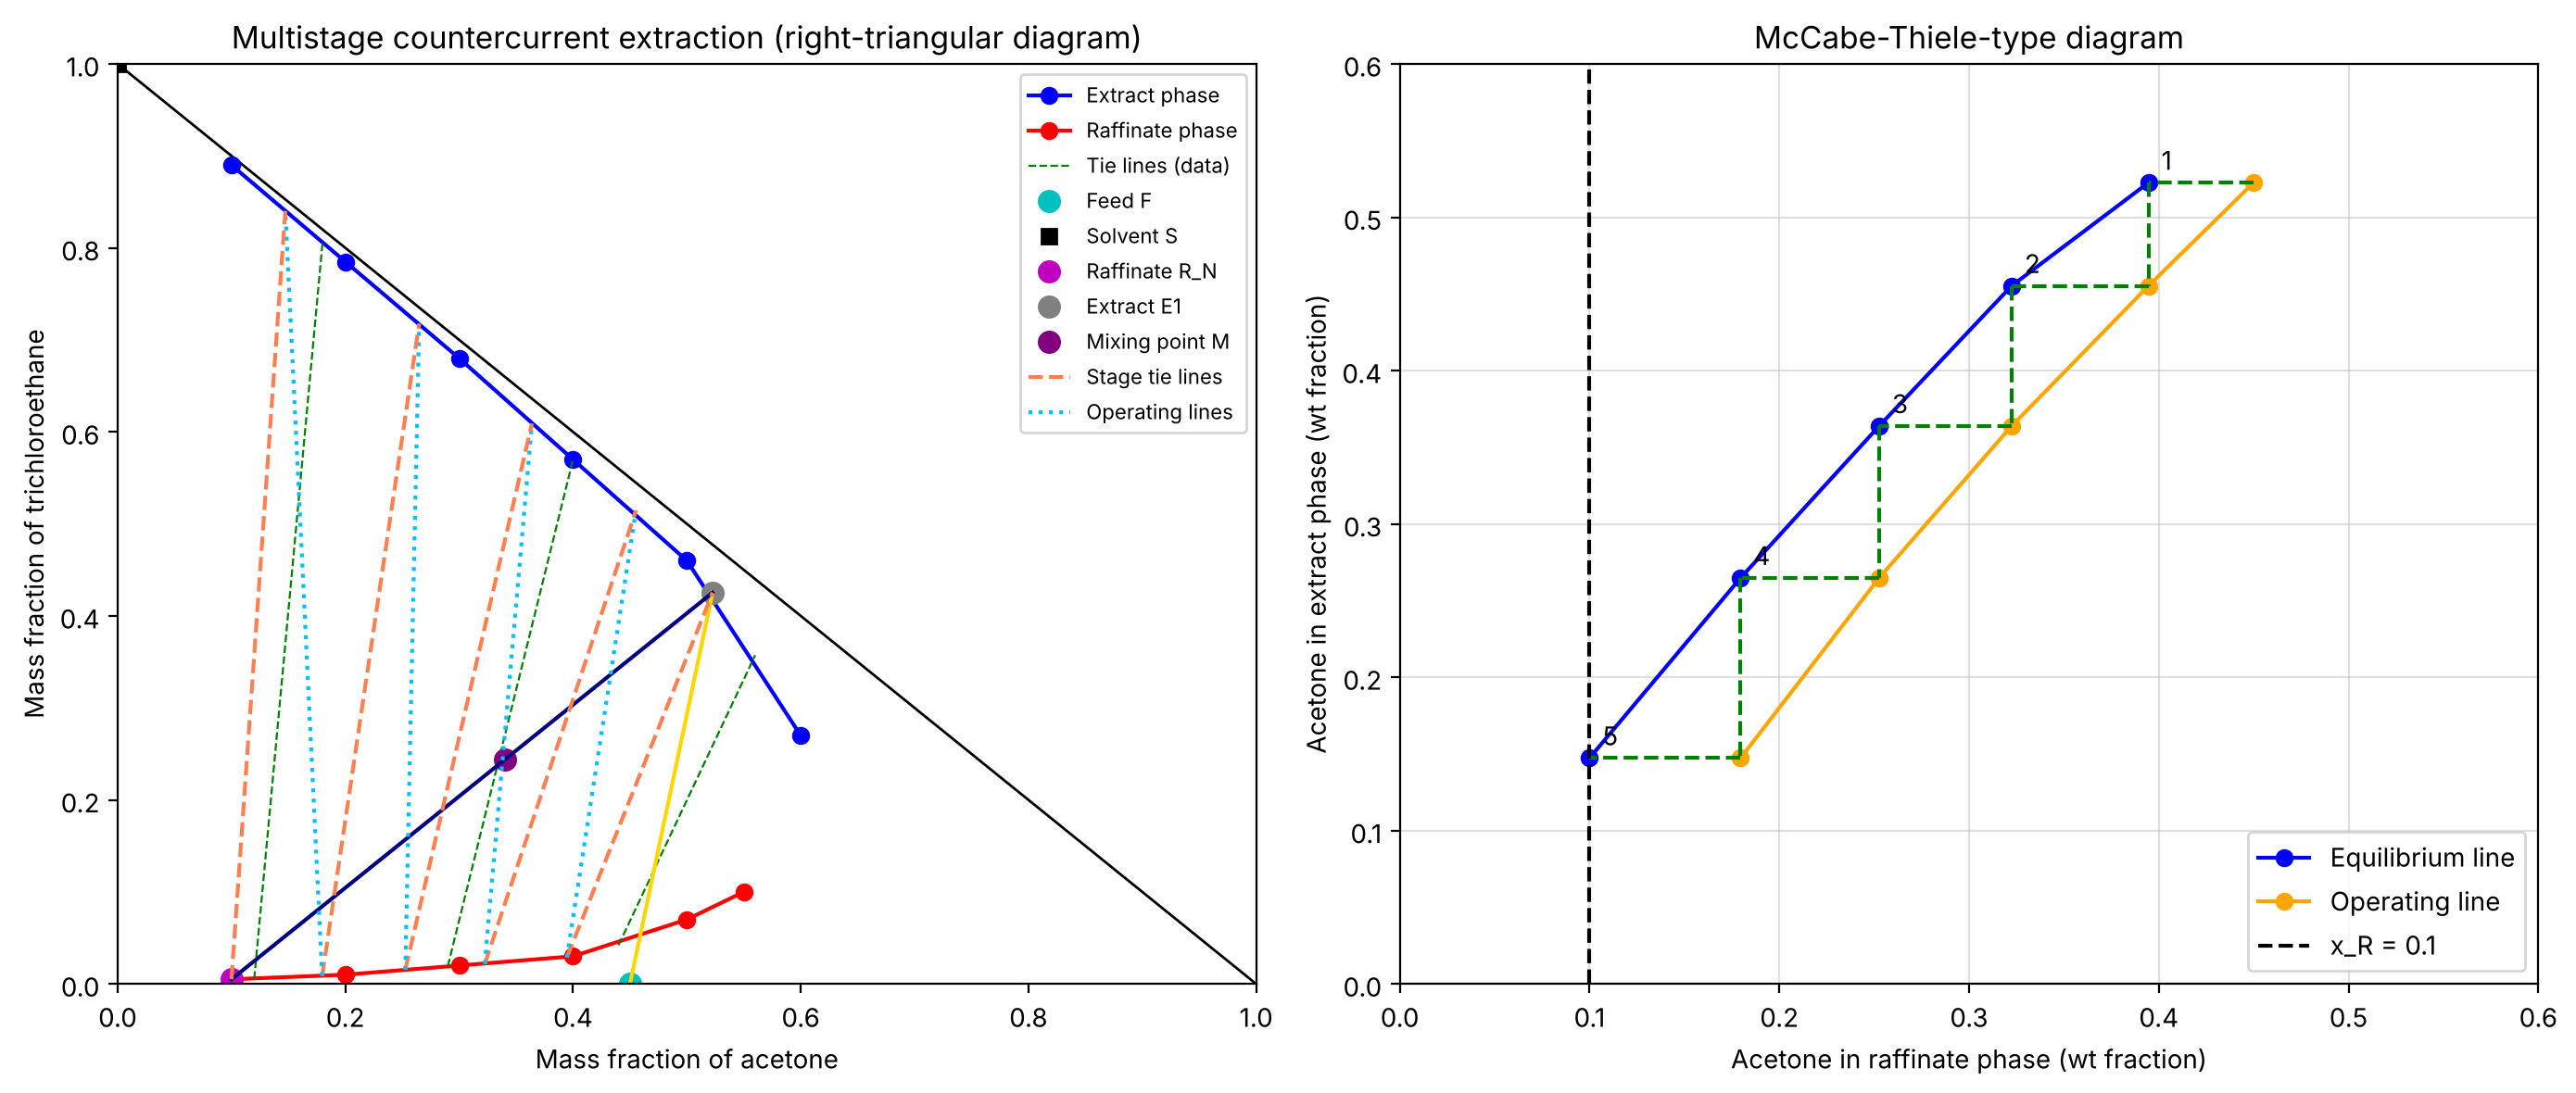

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# --- Right-triangular diagram ---
a = ax[0]
a.plot([0, 1], [1, 0], "k-", lw=1)
xx = np.linspace(0.02, 0.62, 200)
a.plot(ext_acetone, ext_solvent, "bo-", label="Extract phase")
a.plot(raf_acetone, raf_solvent, "ro-", label="Raffinate phase")
for i, (r_, e_) in enumerate(zip(tie_raf, tie_ext)):
    a.plot([r_, e_], [fR(r_), fE(e_)], "g--", lw=0.8, label="Tie lines (data)" if i == 0 else None)
a.plot(*F, "co", ms=8, label="Feed F"); a.plot(*S_pt, "ks", label="Solvent S")
a.plot(*RN, "mo", ms=8, label="Raffinate R_N")
a.plot(*sol["E1"], "o", color="gray", ms=8, label="Extract E1")
a.plot(*sol["M"], "o", color="purple", ms=8, label="Mixing point M")
a.plot([F[0], sol["E1"][0]], [F[1], sol["E1"][1]], color="gold")
a.plot([RN[0], sol["E1"][0]], [RN[1], sol["E1"][1]], color="navy")
for n in range(N):
    a.plot([sol["Rs"][n][0], sol["Es"][n][0]], [sol["Rs"][n][1], sol["Es"][n][1]], "--", color="coral",
           label="Stage tie lines" if n == 0 else None)
    if n < N - 1:
        a.plot([sol["Rs"][n][0], sol["Es"][n + 1][0]], [sol["Rs"][n][1], sol["Es"][n + 1][1]],
               ":", color="deepskyblue", label="Operating lines" if n == 0 else None)
a.set_xlim(0, 1); a.set_ylim(0, 1)
a.set_xlabel("Mass fraction of acetone"); a.set_ylabel("Mass fraction of trichloroethane")
a.set_title("Multistage countercurrent extraction (right-triangular diagram)"); a.legend(fontsize=8)

# --- McCabe-Thiele-type diagram ---
b = ax[1]
yE = sol["Es"][:, 0]; xR = sol["Rs"][:, 0]
xop = np.concatenate([[F[0]], xR[:-1]])
b.plot(xR, yE, "bo-", label="Equilibrium line")
b.plot(xop, yE, "o-", color="orange", label="Operating line")
for i in range(N):
    b.plot([xop[i], xR[i]], [yE[i], yE[i]], "g--")
    b.annotate(str(i + 1), (xR[i], yE[i]), textcoords="offset points", xytext=(5, 5))
    if i < N - 1:
        b.plot([xR[i], xR[i]], [yE[i], yE[i + 1]], "g--")
b.axvline(xN, color="k", ls="--", label=f"x_R = {xN}")
b.set_xlim(0, 0.6); b.set_ylim(0, 0.6); b.grid(alpha=0.4)
b.set_xlabel("Acetone in raffinate phase (wt fraction)"); b.set_ylabel("Acetone in extract phase (wt fraction)")
b.set_title("McCabe-Thiele-type diagram"); b.legend()
plt.tight_layout(); plt.show()

## Step 10. Acetone profile across the stages

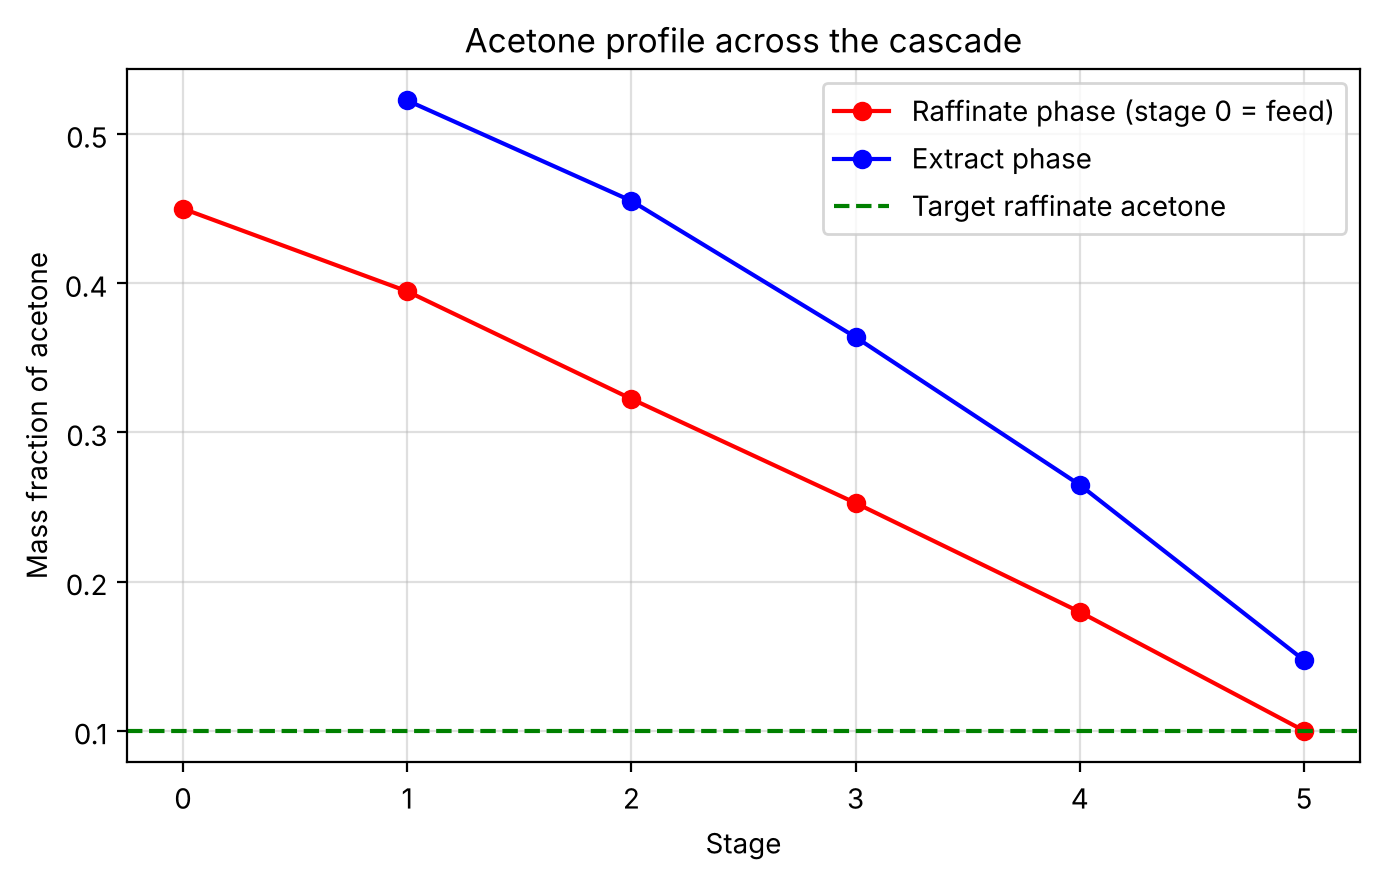

In [10]:
stages_R = list(range(0, N + 1)); stages_E = list(range(1, N + 1))
acetone_R = [F[0]] + list(sol["Rs"][:, 0])
plt.figure(figsize=(7, 4.5))
plt.plot(stages_R, acetone_R, "ro-", label="Raffinate phase (stage 0 = feed)")
plt.plot(stages_E, sol["Es"][:, 0], "bo-", label="Extract phase")
plt.axhline(xN, color="g", ls="--", label="Target raffinate acetone")
plt.xlabel("Stage"); plt.ylabel("Mass fraction of acetone"); plt.grid(alpha=0.4)
plt.title("Acetone profile across the cascade"); plt.legend(); plt.tight_layout(); plt.show()

## Summary
| Item | Result |
|---|---|
| Minimum solvent rate | see Step 4 |
| Solvent at 1.5 × minimum | see Step 4 (needs about 4.7 stages, so **5 ideal stages**) |
| Solvent for exactly 5 stages, 10% acetone raffinate | see Step 6 |
| Stage flows and compositions | Step 7 table |
| Mass balance | closed for all three components on every stage (Step 8) |

**References**
- Seader, J. D., Henley, E. J., & Roper, D. K. (2016). *Separation Process Principles with Applications Using Process Simulators* (4th ed.). Wiley.
- Othmer, D., & Tobias, P. (1942). Liquid-liquid extraction data: partial pressures of ternary liquid systems and the prediction of tie lines. *Industrial & Engineering Chemistry, 34*(6), 696-700.

*Disclaimer: for learning purposes only.*